**Import Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split

**Load MNIST Dataset**

In [ ]:
(X_train_original, y_train_original), (X_test_original, y_test_original) = mnist.load_data()

print("Original training data:", X_train_original.shape)
print("Original testing data :", X_test_original.shape)

Original training data: (60000, 28, 28)
Original testing data : (10000, 28, 28)


**Combine Training and Testing Data**

In [ ]:
X = np.concatenate(
    (X_train_original, X_test_original),
    axis=0
)

y = np.concatenate(
    (y_train_original, y_test_original),
    axis=0
)

print("Total images:", X.shape)
print("Total labels:", y.shape)

Total images: (70000, 28, 28)
Total labels: (70000,)


**Display Some MNIST Images**

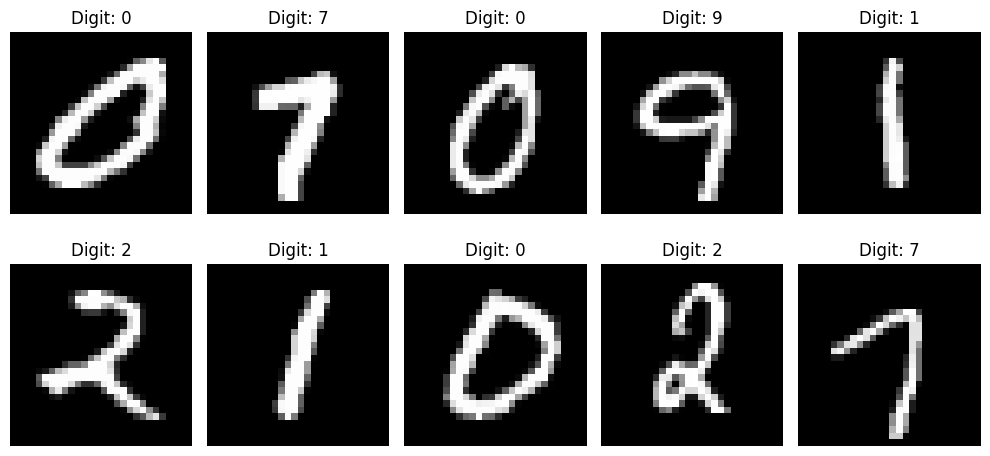

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title("Digit: " + str(y_train[i]))

    plt.axis('off')

plt.tight_layout()
plt.show()

**Train test split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print('Train images',X_train.shape)
print('Test images',X_test.shape)

Train images (56000, 28, 28)
Test images (14000, 28, 28)


**Normalize Images**

In [ ]:
X_train = X_train / 255.0
X_test = X_test / 255.0

**Add Channel Dimension**

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New training shape:", X_train.shape)
print("New testing shape:", X_test.shape)

New training shape: (56000, 28, 28, 1)
New testing shape: (14000, 28, 28, 1)


**Create CNN Mode**

In [ ]:
model = Sequential([

    # First CNN layer
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),

    # First MaxPooling layer
    MaxPooling2D(
        pool_size=(3, 3),
        strides=(1, 1)
    ),


    # Second CNN layer
    Conv2D(
        64,
        kernel_size=(3, 3),
        activation='relu'
    ),

    # Second MaxPooling layer
    MaxPooling2D(
        pool_size=(3, 3),
        strides=(1, 1)
    ),


    # Convert feature maps into 1D
    Flatten(),

    # Dense layer
    Dense(
        64,
        activation='relu'
    ),

    # Output layer
    Dense(
        10,
        activation='softmax'
    )
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Display Model Architecture**

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,657,930 (6.32 MB)

 Trainable params: 1,657,930 (6.32 MB)

 Non-trainable params: 0 (0.00 B)

**Compile Model**

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

**EarlyStopping Callback**

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

**Train Model**

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.125,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9656 - loss: 0.1120 - val_accuracy: 0.9860 - val_loss: 0.0450
Epoch 2/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9862 - loss: 0.0432 - val_accuracy: 0.9834 - val_loss: 0.0494
Epoch 3/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9914 - loss: 0.0287 - val_accuracy: 0.9870 - val_loss: 0.0414
Epoch 4/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9925 - loss: 0.0234 - val_accuracy: 0.9859 - val_loss: 0.0475
Epoch 5/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9941 - loss: 0.0184 - val_accuracy: 0.9791 - val_loss: 0.0759
Epoch 6/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9952 - loss: 0.0142 - val_accuracy: 0.9900 - val_loss: 0.0372
Epoch 7/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9959 - loss: 0.0134 - val_accuracy: 0.9903 - val_loss: 0.0354
Epoch 8/20
1532/1532 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9969 - loss: 0.0095 -

**Evaluate on Test Data**

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9900 - loss: 0.0418
Test Loss: 0.041794970631599426
Test Accuracy: 0.9900000095367432


**Training Accuracy vs Testing Accuracy**

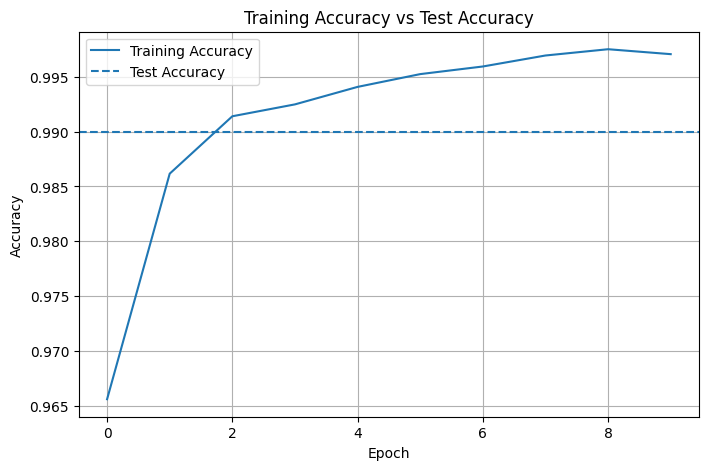

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.axhline(
    test_accuracy,
    linestyle='--',
    label='Test Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training Accuracy vs Test Accuracy')

plt.legend()
plt.grid(True)

plt.show()

**Display Predictions**

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


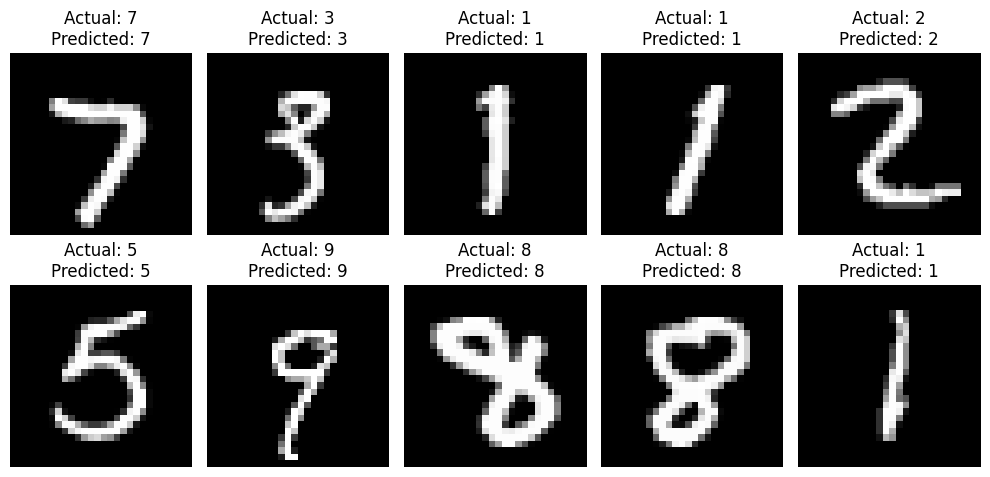

In [ ]:
predictions = model.predict(X_test)

predicted_classes = np.argmax(
    predictions,
    axis=1
)


plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap='gray'
    )

    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(predicted_classes[i])
    )

    plt.axis('off')

plt.tight_layout()
plt.show()